In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_absolute_error

In [2]:
food_names = [
    "Apple",
    "Banana",
    "Pizza",
    "Burger",
    "Rice"
]

# Approximate calories for demonstration
calories = {
    "Apple": 95,
    "Banana": 105,
    "Pizza": 285,
    "Burger": 350,
    "Rice": 200
}

print(food_names)
print(calories)

['Apple', 'Banana', 'Pizza', 'Burger', 'Rice']
{'Apple': 95, 'Banana': 105, 'Pizza': 285, 'Burger': 350, 'Rice': 200}


In [3]:
np.random.seed(42)

IMG_SIZE = 32
IMAGES_PER_CLASS = 200

X = []
y = []
calorie_values = []

for class_id, food in enumerate(food_names):

    for i in range(IMAGES_PER_CLASS):

        image = np.zeros((IMG_SIZE, IMG_SIZE))

        # Apple pattern
        if class_id == 0:
            image[8:25, 8:25] = 1
            image[5:10, 12:20] = 1

        # Banana pattern
        elif class_id == 1:
            for j in range(8, 25):
                image[j, j-5:j] = 1

        # Pizza pattern
        elif class_id == 2:
            for j in range(8, 25):
                width = j - 7
                image[j, 16-width//2:16+width//2] = 1

        # Burger pattern
        elif class_id == 3:
            image[8:12, 7:25] = 1
            image[13:17, 7:25] = 1
            image[18:22, 7:25] = 1

        # Rice pattern
        elif class_id == 4:
            image[10:22, 8:24] = 1
            image[7:12, 11:21] = 1

        # Add small random noise
        noise = np.random.normal(0, 0.08, (IMG_SIZE, IMG_SIZE))

        image = image + noise

        X.append(image)
        y.append(class_id)
        calorie_values.append(calories[food])

X = np.array(X)
y = np.array(y)
calorie_values = np.array(calorie_values)

print("Total images:", len(X))
print("Image size:", X.shape)

Total images: 1000
Image size: (1000, 32, 32)


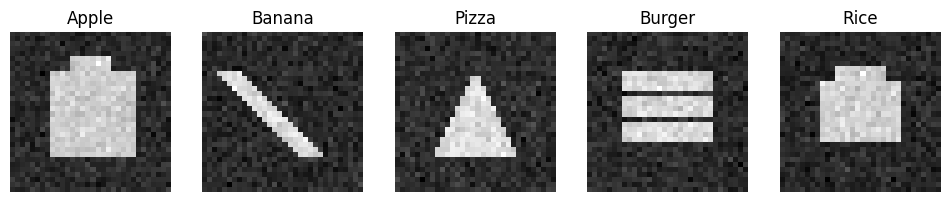

In [4]:
plt.figure(figsize=(12, 4))

for i in range(5):

    plt.subplot(1, 5, i + 1)

    plt.imshow(X[i * IMAGES_PER_CLASS], cmap="gray")

    plt.title(food_names[i])

    plt.axis("off")

plt.show()

In [5]:
X = X.reshape(X.shape[0], -1)

print("New shape:", X.shape)

New shape: (1000, 1024)


In [6]:
X_train, X_test, y_train, y_test, cal_train, cal_test = train_test_split(
    X,
    y,
    calorie_values,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 800
Testing: 200


In [7]:
classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [8]:
classifier.fit(X_train, y_train)

print("Food classification training completed!")

Food classification training completed!


In [9]:
food_predictions = classifier.predict(X_test)

In [10]:
for i in range(10):

    predicted_food = food_names[food_predictions[i]]
    actual_food = food_names[y_test[i]]

    print(
        "Actual:",
        actual_food,
        "| Predicted:",
        predicted_food
    )

Actual: Pizza | Predicted: Pizza
Actual: Apple | Predicted: Apple
Actual: Banana | Predicted: Banana
Actual: Banana | Predicted: Banana
Actual: Burger | Predicted: Burger
Actual: Apple | Predicted: Apple
Actual: Pizza | Predicted: Pizza
Actual: Burger | Predicted: Burger
Actual: Pizza | Predicted: Pizza
Actual: Rice | Predicted: Rice


In [11]:
accuracy = accuracy_score(y_test, food_predictions)

print("Food Recognition Accuracy:", accuracy * 100, "%")

Food Recognition Accuracy: 100.0 %


In [12]:
calorie_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

In [13]:
calorie_model.fit(X_train, cal_train)

print("Calorie prediction training completed!")

Calorie prediction training completed!


In [14]:
calorie_predictions = calorie_model.predict(X_test)

print("Actual calories:", cal_test[:10])
print("Predicted calories:", calorie_predictions[:10])

Actual calories: [285  95 105 105 350  95 285 350 285 200]
Predicted calories: [285.  95. 105. 105. 350.  95. 285. 350. 285. 200.]


In [15]:
error = mean_absolute_error(
    cal_test,
    calorie_predictions
)

print("Mean Absolute Error:", error)

Mean Absolute Error: 0.0


In [16]:
index = 10

sample_image = X_test[index]

food_prediction = classifier.predict([sample_image])[0]

calorie_prediction = calorie_model.predict([sample_image])[0]

print("Predicted Food:", food_names[food_prediction])
print("Estimated Calories:", round(calorie_prediction), "kcal")

Predicted Food: Apple
Estimated Calories: 95 kcal


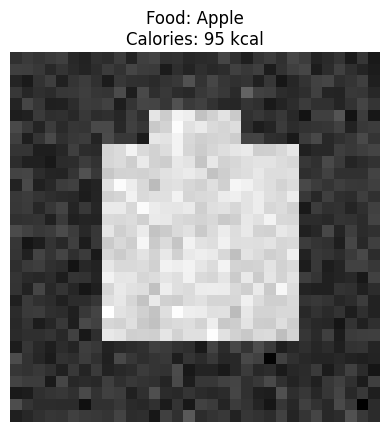

In [17]:
plt.imshow(
    sample_image.reshape(32, 32),
    cmap="gray"
)

plt.title(
    "Food: " + food_names[food_prediction] +
    "\nCalories: " + str(round(calorie_prediction)) + " kcal"
)

plt.axis("off")
plt.show()